**Assignment 1 – Heart Disease (Cleveland Database)**

Group: name1, name2, name3

The file processed.cleveland.data must be in the same folder as this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "processed.cleveland.data"       # relative path to the provided dataset
COLUMNS = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]
df = pd.read_csv(DATA_PATH, header=None, names=COLUMNS, na_values="?")   # "?" = missing value
print(df.shape)

(303, 14)


**Task 2 – Classifiers for the 5-class target (num = 0 to 4)**

We train four classifiers (Logistic Regression, kNN, Random Forest, SVM) and compare them with a baseline that always predicts the most frequent class. Before training, missing values are filled with the most frequent value, the nominal features cp, restecg, slope and thal are one-hot encoded, and all features are standardised. This is done inside a pipeline, so it is learned on the training data only.

In [2]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42

features = [c for c in df.columns if c != "num"]
X = df[features]
y_multi = df["num"].values

NOMINAL = ["cp", "restecg", "slope", "thal"]      # labels, not real numbers -> one-hot
OTHER = [c for c in features if c not in NOMINAL]

def make_preprocessor():
    nominal = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    other = Pipeline([("impute", SimpleImputer(strategy="most_frequent"))])
    return Pipeline([("columns", ColumnTransformer([("nom", nominal, NOMINAL),
                                                    ("oth", other, OTHER)])),
                     ("scale", StandardScaler())])

def make_models():
    return {
        "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "kNN (k=15)": KNeighborsClassifier(n_neighbors=15),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
        "SVM (RBF)": SVC(kernel="rbf", random_state=RANDOM_STATE),
    }

def pipe(model):
    # preprocessing is fitted on the training folds only -> no data leakage
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

**Evaluation**

With only 303 patients a single train/test split is very noisy, so we use stratified 5-fold cross-validation repeated 10 times and report mean and standard deviation. Sensitivity and specificity are defined for two classes, so for the 5 classes we compute them for each class against the rest and take the average.

                         accuracy        sensitivity        specificity       
                             mean    std        mean    std        mean    std
model                                                                         
Baseline (most frequent)    0.541  0.005       0.200  0.000       0.800  0.000
Logistic Regression         0.586  0.043       0.324  0.050       0.878  0.013
kNN (k=15)                  0.582  0.037       0.289  0.051       0.865  0.013
Random Forest               0.575  0.035       0.290  0.046       0.864  0.012
SVM (RBF)                   0.581  0.037       0.289  0.043       0.863  0.013


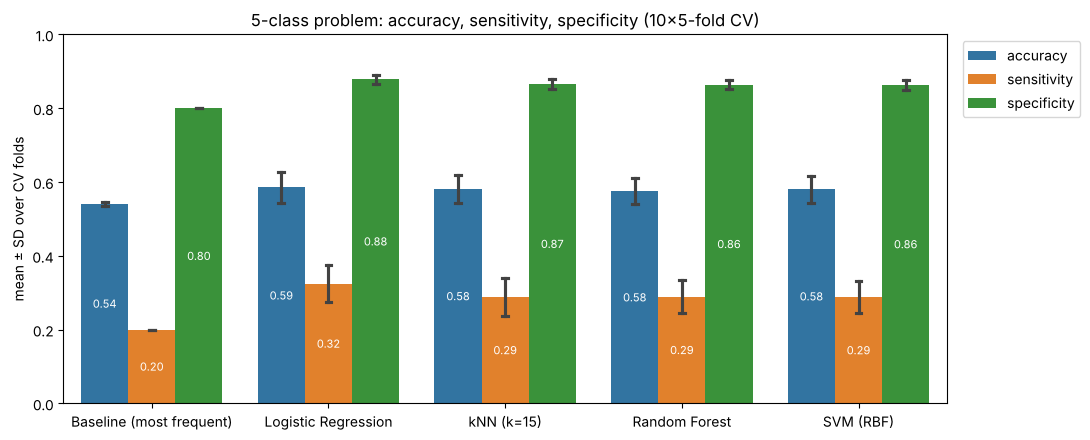

In [3]:
def sens_spec(y_true, y_pred, labels):
    # one-vs-rest sensitivity and specificity per class, then macro average
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    tp = np.diag(cm)
    fn = cm.sum(axis=1) - tp
    fp = cm.sum(axis=0) - tp
    tn = cm.sum() - tp - fn - fp
    with np.errstate(invalid="ignore", divide="ignore"):
        sens = tp / (tp + fn)
        spec = tn / (tn + fp)
    if len(labels) == 2:                      # binary case: positive class = 1
        return sens[1], spec[1]
    return np.nanmean(sens), np.nanmean(spec)

def evaluate(y, labels):
    # stratified 5-fold CV, repeated 10 times = 50 train/test splits
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
    rows = []
    for name, model in make_models().items():
        for tr, te in cv.split(X, y):
            m = pipe(clone(model)).fit(X.iloc[tr], y[tr])
            pred = m.predict(X.iloc[te])
            se, sp = sens_spec(y[te], pred, labels)
            rows.append({"model": name, "accuracy": accuracy_score(y[te], pred),
                         "sensitivity": se, "specificity": sp})
    return pd.DataFrame(rows)

def grouped_bar(res, title):
    long = res.melt(id_vars="model", var_name="metric", value_name="value")
    fig, ax = plt.subplots(figsize=(11, 4.5))
    sns.barplot(data=long, x="model", y="value", hue="metric", errorbar="sd", capsize=0.1, ax=ax)
    ax.set(ylim=(0, 1), ylabel="mean ± SD over CV folds", xlabel="", title=title)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    for c in ax.containers:
        if hasattr(c, "datavalues"):
            ax.bar_label(c, fmt="%.2f", fontsize=8, label_type="center", color="white")
    plt.tight_layout()
    plt.show()

res_multi = evaluate(y_multi, labels=[0, 1, 2, 3, 4])
print(res_multi.groupby("model", sort=False).agg(["mean", "std"]).round(3))
grouped_bar(res_multi, "5-class problem: accuracy, sensitivity, specificity (10x5-fold CV)")

**Confusion matrices**

Each patient is predicted once by a model that did not see this patient during training.

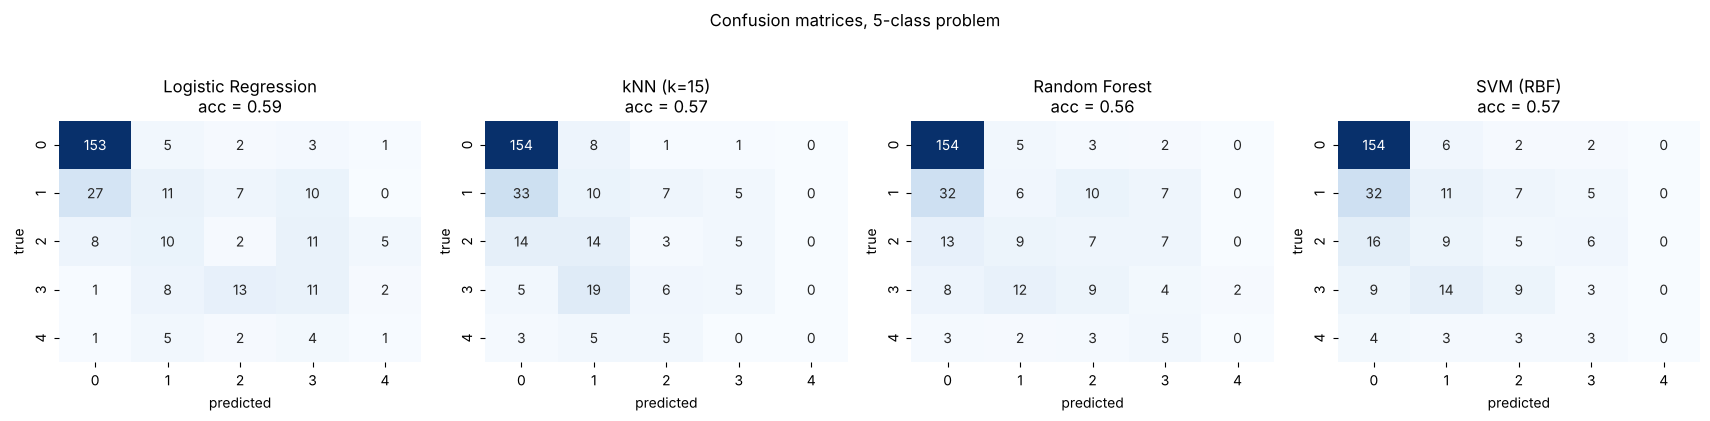

In [4]:
def confusion_heatmaps(y, labels, title):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    models = {k: v for k, v in make_models().items() if not k.startswith("Baseline")}
    fig, axes = plt.subplots(1, len(models), figsize=(4.3 * len(models), 4))
    preds = {}
    for ax, (name, model) in zip(axes, models.items()):
        pred = cross_val_predict(pipe(model), X, y, cv=cv)
        preds[name] = pred
        cm = confusion_matrix(y, pred, labels=labels)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=labels, yticklabels=labels)
        ax.set(title=f"{name}\nacc = {accuracy_score(y, pred):.2f}",
               xlabel="predicted", ylabel="true")
    plt.suptitle(title, y=1.04)
    plt.tight_layout()
    plt.show()
    return preds

preds_multi = confusion_heatmaps(y_multi, [0, 1, 2, 3, 4], "Confusion matrices, 5-class problem")

**Observations**

All models reach an accuracy of only about 0.58, which is barely better than the baseline (0.54) that always predicts "no disease". The average sensitivity is low (about 0.3): the confusion matrices show that most class 0 patients are classified correctly, but patients of classes 1 to 4 are often predicted as healthy or confused with each other, and class 4 is almost never found. The specificity looks high (about 0.87), but this is partly because in a one-vs-rest view most patients are negatives for each class. The reason is that there are few patients per severity class and the features hardly differ between classes 1 to 4.